# EEG motor-imagery decoding — exploratory notebook

**Question:** How do sensor-level oscillatory patterns and within-participant decoding performance vary during imagined left- versus right-fist movement?

This notebook complements [`eeg_pipeline.py`](eeg_pipeline.py). The Python script runs the complete, reproducible analysis; this notebook walks through **one recording**, examines intermediate signals, optionally runs **held-out-run decoding**, and explores **multi-participant results** generated by the script.

**Data:** [PhysioNet EEG Motor Movement/Imagery (EEGBCI)](https://physionet.org/content/eegmmidb/1.0.0/); *runs 4, 8 and 12* are imagined left/right fist movement. Only public recordings are used. After running the notebook locally, saved single-recording preview figures will show **subject S004, run R04** (or your selected recording); they are not aggregate decoding results.

**Limitations:** Offline analysis only; not a real-time BCI. Within-subject leave-one-run-out performance does **not** measure transfer to new individuals. ICA-based ocular cleaning is off by default because there are no dedicated EOG channels.

Run the cells from top to bottom in the repository root. Missing datasets or group-result files are reported, not downloaded silently.

## 1. Setup and choose an example recording

Set `SUBJECT` to any participant whose `S###R04.edf` file is in `data/`. The notebook searches both flat and participant-folder layouts. The decoder later needs **all three** imagery runs (04, 08, 12).

In [1]:
from pathlib import Path
from io import BytesIO
import csv
import json

import numpy as np
import matplotlib.pyplot as plt
import mne
from IPython.display import Image, display

from eeg_pipeline import (
    RUNS, read_recording, preprocess, condition_tfr, mean_erd,
    laterality_effect, load_subject, decode_held_out_runs,
)

SUBJECT = 2
EXAMPLE_RUN = 4
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")

# Render a static PNG so figures work in Jupyter and on GitHub even when
# the command-line pipeline has selected a noninteractive Matplotlib backend.
def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

mne.set_log_level("WARNING")
example_name = f"S{SUBJECT:03d}R{EXAMPLE_RUN:02d}.edf"
found = sorted(DATA_DIR.rglob(example_name)) if DATA_DIR.exists() else []
example_path = found[0] if found else None
raw = read_recording(example_path) if example_path is not None else None

if raw is None:
    print(f"Missing {example_name}. Place it anywhere inside data/ and rerun.")
else:
    print(f"Loaded {example_path}")
    print(f"{len(raw.ch_names)} channels; {raw.info['sfreq']:.0f} Hz; "
          f"{raw.times[-1]:.1f} seconds; events: {set(raw.annotations.description)}")

Loaded data/S002/S002R04.edf
64 channels; 160 Hz; 123.0 seconds; events: {'T2', 'T0', 'T1'}


## 2. Inspect the continuous EEG

The two motor-cortex electrodes **C3** (left hemisphere) and **C4** (right hemisphere) provide useful initial signals to inspect. The traces are measured in microvolts and contain background brain activity plus noise and artifacts; they are **not yet decoded**.

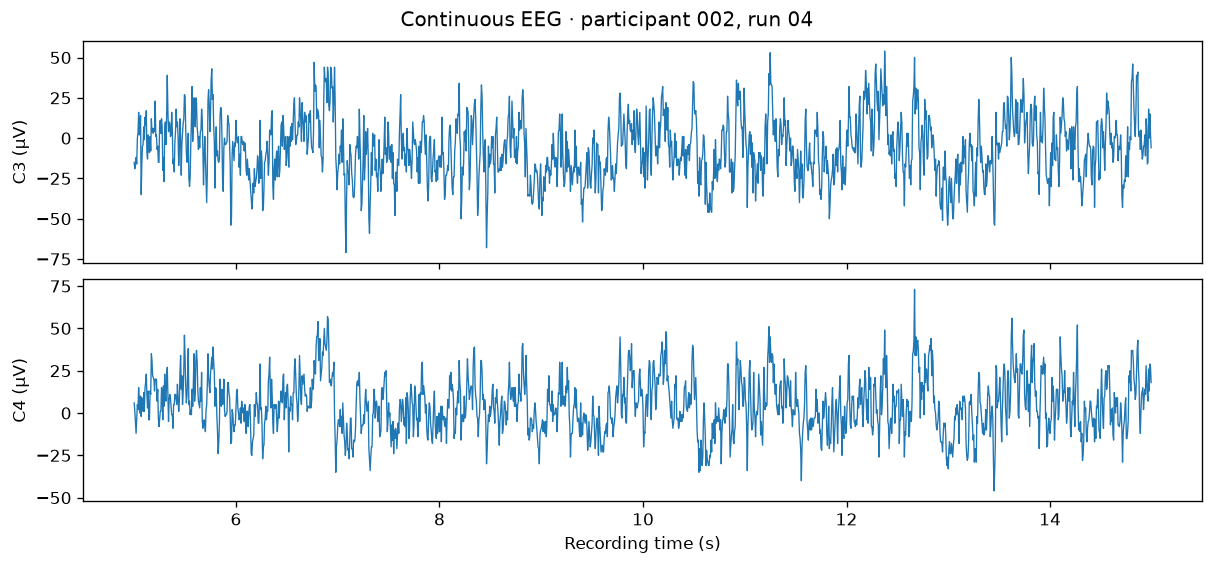

In [2]:
if raw is not None:
    start_sec, stop_sec = 5.0, 15.0
    sfreq = raw.info["sfreq"]
    i0, i1 = int(start_sec * sfreq), int(stop_sec * sfreq)
    times = raw.times[i0:i1]
    segment_uv = 1e6 * raw.get_data(picks=["C3", "C4"], start=i0, stop=i1)
    fig, axs = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, layout="constrained")
    for ch_idx, ch in enumerate(("C3", "C4")):
        axs[ch_idx].plot(times, segment_uv[ch_idx], linewidth=0.8)
        axs[ch_idx].set(ylabel=f"{ch} (µV)")
    axs[-1].set(xlabel="Recording time (s)")
    fig.suptitle(f"Continuous EEG · participant {SUBJECT:03d}, run {EXAMPLE_RUN:02d}")
    show_figure(fig)

## 3. Preprocess and extract cue-aligned trials

Reuse the same function as the command-line pipeline: **1–40 Hz bandpass**, **average reference**, and **−1 to +4 s epochs** around T1 (left imagery) and T2 (right imagery). No 60-Hz notch is needed after a 40-Hz low-pass filter. The default analysis does **not** remove ICA components automatically.

Below, a before/after signal comparison illustrates filtering and referencing; this plot is descriptive, not proof that all artifacts are removed.

15 imagery epochs: T1/left=7, T2/right=8
Epoch duration: -1.0 to 4.0 s


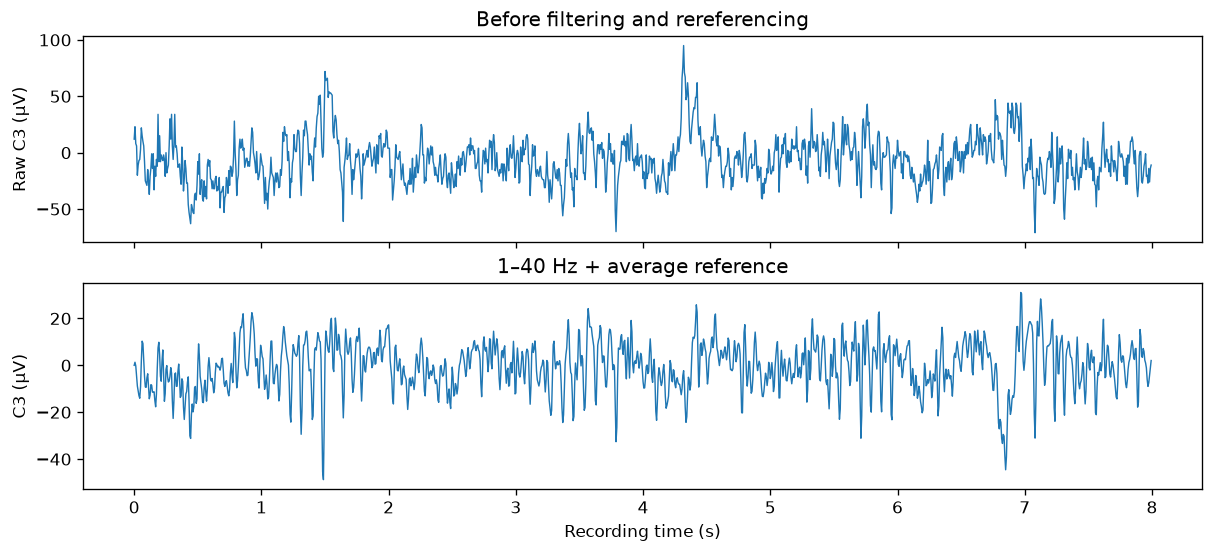

In [3]:
epochs = preprocess(raw, use_ica=False) if raw is not None else None
if epochs is not None:
    print(f"{len(epochs)} imagery epochs: "
          f"T1/left={len(epochs['T1'])}, T2/right={len(epochs['T2'])}")
    print(f"Epoch duration: {epochs.tmin:.1f} to {epochs.tmax:.1f} s")
    preview_filtered = raw.copy().filter(1.0, 40.0, verbose="ERROR")
    preview_filtered.set_eeg_reference("average", projection=False, verbose="ERROR")
    sample_len = int(8 * raw.info["sfreq"])
    t = raw.times[:sample_len]
    original = 1e6 * raw.get_data(picks=["C3"], stop=sample_len).ravel()
    cleaned = 1e6 * preview_filtered.get_data(picks=["C3"], stop=sample_len).ravel()
    fig, axs = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True, layout="constrained")
    axs[0].plot(t, original, linewidth=0.85)
    axs[0].set(ylabel="Raw C3 (µV)", title="Before filtering and rereferencing")
    axs[1].plot(t, cleaned, linewidth=0.85)
    axs[1].set(xlabel="Recording time (s)", ylabel="C3 (µV)",
               title="1–40 Hz + average reference")
    show_figure(fig)

## 4. Power spectrum: where are the mu/beta rhythms?

Motor imagery often modulates **mu (8–12 Hz)** and **beta (13–30 Hz)** power. Welch power spectral density provides a frequency-domain view; a power spectrum alone does **not** tell us when the task-related change occurred.

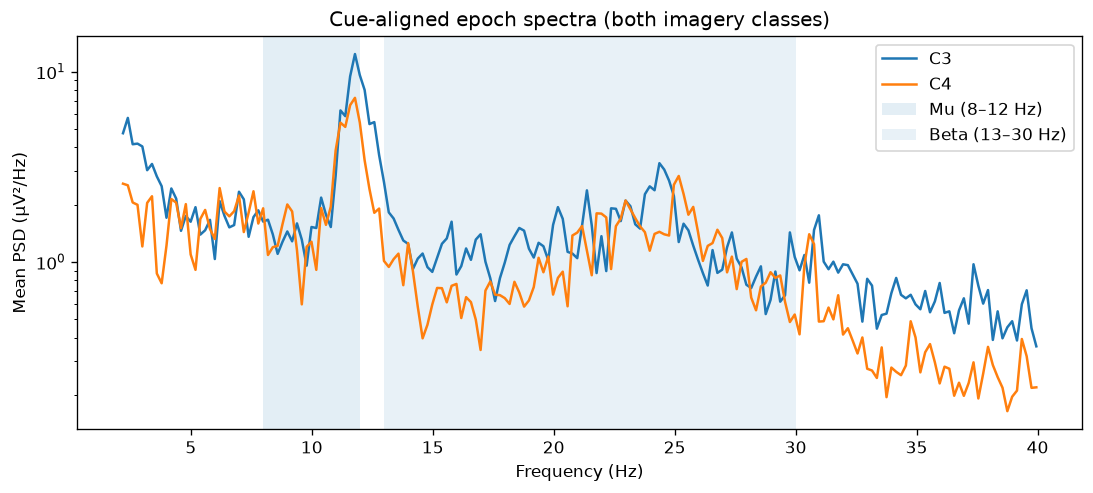

In [4]:
if epochs is not None:
    psd = epochs.compute_psd(method="welch", fmin=2, fmax=40,
                             picks=["C3", "C4"], verbose="ERROR")
    mean_power = psd.get_data().mean(axis=0) * 1e12  # V²/Hz -> µV²/Hz
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    for idx, ch in enumerate(psd.ch_names):
        ax.semilogy(psd.freqs, mean_power[idx], label=ch)
    ax.axvspan(8, 12, alpha=0.12, label="Mu (8–12 Hz)")
    ax.axvspan(13, 30, alpha=0.10, label="Beta (13–30 Hz)")
    ax.set(xlabel="Frequency (Hz)", ylabel="Mean PSD (µV²/Hz)",
           title="Cue-aligned epoch spectra (both imagery classes)")
    ax.legend()
    show_figure(fig)

## 5. Event-related desynchronization: time–frequency analysis

Morlet wavelets estimate power **over both time and frequency**. Power is expressed as **percentage change** relative to the pre-cue baseline (**−0.8 to −0.2 s**). Negative changes indicate suppression (ERD); positive changes indicate enhancement (ERS). Because single-run estimates are noisy, interpret individual heatmaps cautiously.

The panels show **contralateral** motor sites: C4 for imagined left-fist movement and C3 for imagined right-fist movement.

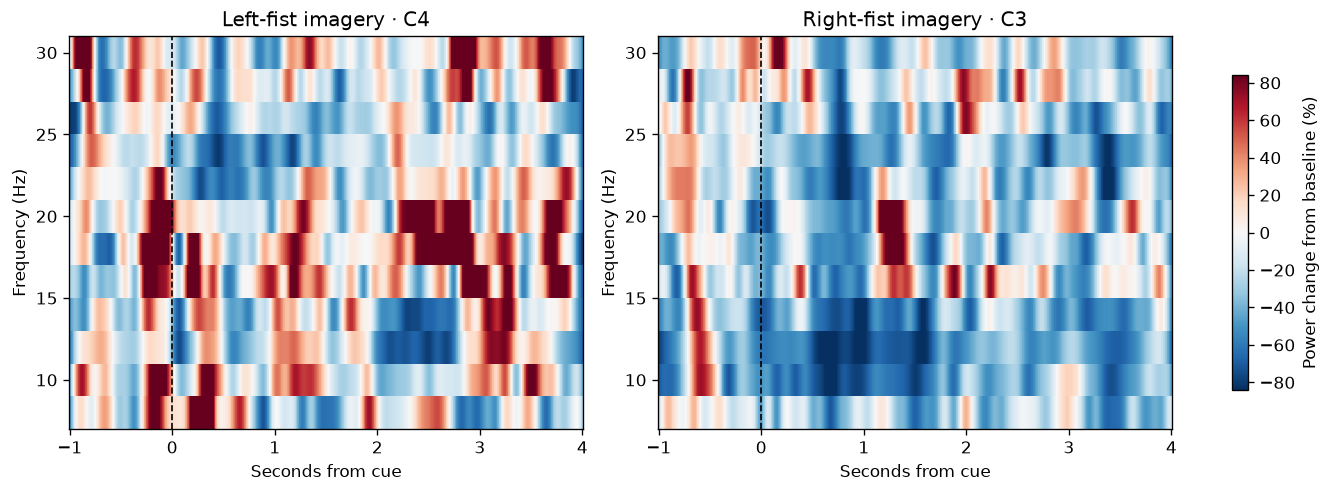

Single-run mean contra − ipsi ERD: -0.21% points
Negative = stronger contralateral power suppression; this is descriptive.


In [5]:
if epochs is not None:
    left_tfr = condition_tfr(epochs, "T1")
    right_tfr = condition_tfr(epochs, "T2")
    panels = [(left_tfr, "C4", "Left-fist imagery · C4"),
              (right_tfr, "C3", "Right-fist imagery · C3")]
    scale = max(20.0, float(np.percentile(
        np.concatenate([np.abs(tfr.data).ravel() for tfr, _, _ in panels]), 95)))
    fig, axs = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, (tfr, ch, title) in zip(axs, panels):
        idx = tfr.ch_names.index(ch)
        im = ax.pcolormesh(tfr.times, tfr.freqs, tfr.data[idx],
                           shading="auto", cmap="RdBu_r", vmin=-scale, vmax=scale)
        ax.axvline(0, linestyle="--", linewidth=1, color="black")
        ax.set(xlabel="Seconds from cue", ylabel="Frequency (Hz)", title=title)
    fig.colorbar(im, ax=axs, label="Power change from baseline (%)", shrink=0.8)
    show_figure(fig)
    laterality = laterality_effect(left_tfr, right_tfr)
    print(f"Single-run mean contra − ipsi ERD: {laterality:+.2f}% points")
    print("Negative = stronger contralateral power suppression; this is descriptive.")

## 6. Decode imagery using **held-out recording runs**

This part requires **R04, R08, and R12 for the same participant**, not just the single preview file. For each fold, the decoder fits CSP features and LDA using two runs, then evaluates on the third. The classification window is **0.5–3.5 s** after the cue with an **8–30 Hz** bandpass.

This is **within-participant**, run-held-out validation; it cannot establish performance for a previously unseen participant.

Participant 002: 91.1% held-out-run accuracy across 45 trials
Majority-class baseline: 51.1%


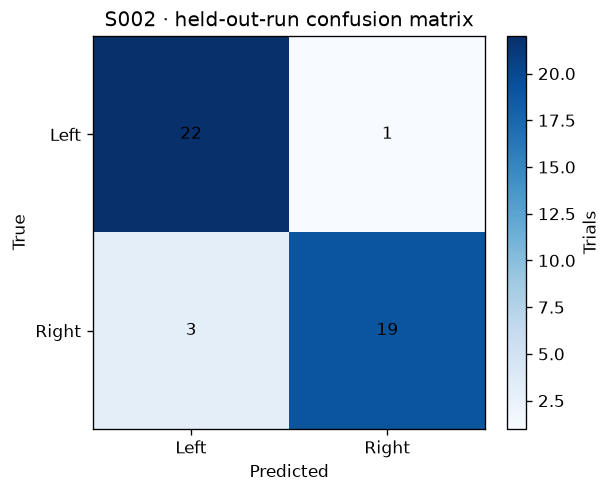

In [6]:
available = {r: sorted(DATA_DIR.rglob(f"S{SUBJECT:03d}R{r:02d}.edf"))
             if DATA_DIR.exists() else [] for r in RUNS}
if not all(available.values()):
    missing = [f"S{SUBJECT:03d}R{r:02d}.edf" for r, paths in available.items()
               if not paths]
    print("To run held-out-run decoding, add: " + ", ".join(missing))
else:
    subject_epochs, run_groups = load_subject(
        SUBJECT, DATA_DIR, use_ica=False, local_only=True)
    accuracy, cm, true_labels, predicted_labels = decode_held_out_runs(
        subject_epochs, run_groups)
    majority_baseline = max(np.mean(true_labels == 0), np.mean(true_labels == 1))
    print(f"Participant {SUBJECT:03d}: {accuracy:.1%} held-out-run accuracy "
          f"across {len(true_labels)} trials")
    print(f"Majority-class baseline: {majority_baseline:.1%}")
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    im = ax.imshow(cm, cmap="Blues")
    for (i, j), count in np.ndenumerate(cm):
        ax.text(j, i, str(count), ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1],
           xticklabels=["Left", "Right"], yticklabels=["Left", "Right"],
           xlabel="Predicted", ylabel="True",
           title=f"S{SUBJECT:03d} · held-out-run confusion matrix")
    fig.colorbar(im, ax=ax, label="Trials")
    show_figure(fig)

## 7. Compare participants using pipeline outputs

First run the **full** Python script in a terminal (example below). It writes `results/subject_results.csv` and `results/summary.json`; this notebook **reads** those files instead of redundantly reprocessing every participant.

```bash
python eeg_pipeline.py --subjects 1 2 3 4 5 --local-only
# or, once files for 1–30 are available:
python eeg_pipeline.py --subjects $(seq 1 30) --local-only
```

The dashed 50% line is the expected chance accuracy for approximately balanced left/right trials; sampling variability can produce accuracy above or below it even without a reliable signal.

Participants: 30; mean accuracy: 60.4%; range: 44.4%–100.0%
Mean majority-class baseline: 51.7%


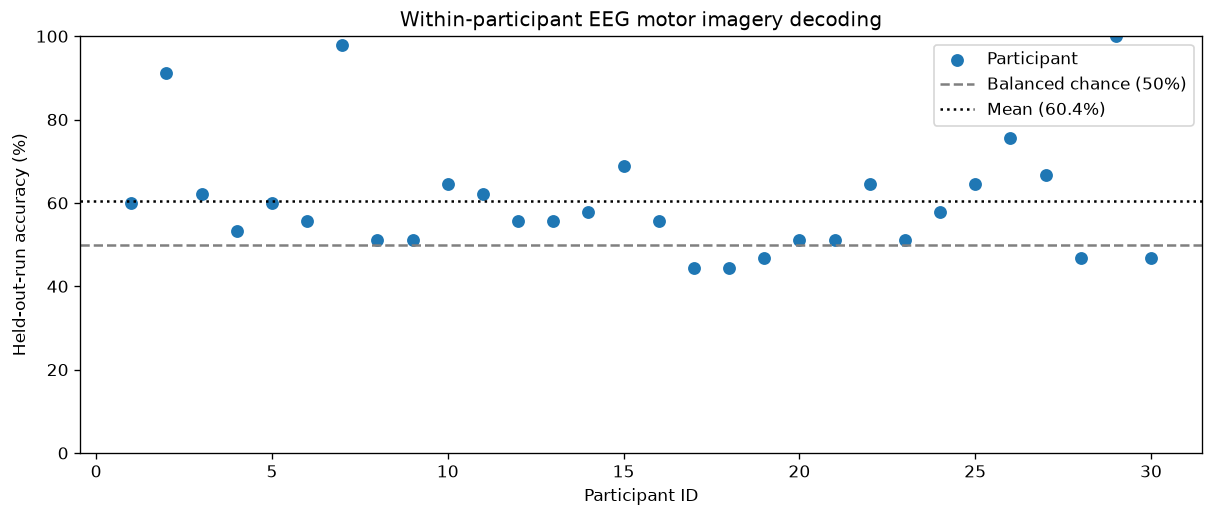

In [7]:
results_path = RESULTS_DIR / "subject_results.csv"
rows = []
if not results_path.is_file():
    print("No group results found. Run eeg_pipeline.py first to generate results/subject_results.csv.")
else:
    with results_path.open(newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    rows = sorted(rows, key=lambda r: int(r["subject"]))
    subjects = np.array([int(r["subject"]) for r in rows])
    accuracies = np.array([float(r["accuracy"]) for r in rows])
    baselines = np.array([float(r["majority_class_baseline"]) for r in rows])
    print(f"Participants: {len(rows)}; mean accuracy: {accuracies.mean():.1%}; "
          f"range: {accuracies.min():.1%}–{accuracies.max():.1%}")
    print(f"Mean majority-class baseline: {baselines.mean():.1%}")
    fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
    ax.scatter(subjects, accuracies * 100, s=45, label="Participant")
    ax.axhline(50, linestyle="--", color="gray", label="Balanced chance (50%)")
    ax.axhline(accuracies.mean() * 100, linestyle=":", color="black",
               label=f"Mean ({accuracies.mean():.1%})")
    ax.set(xlabel="Participant ID", ylabel="Held-out-run accuracy (%)",
           ylim=(0, 100), title="Within-participant EEG motor imagery decoding")
    ax.legend()
    show_figure(fig)

## 8. Exploratory research question: is ERD lateralization associated with decodability?

The pipeline reports each participant's **contralateral minus ipsilateral** change in mu/beta power (more negative values imply stronger contralateral ERD). We can *describe* whether those values relate to within-participant accuracy; this is **not** a causal test, a calibrated predictor, or a pre-registered hypothesis. Especially with small samples, outliers can dominate correlations.

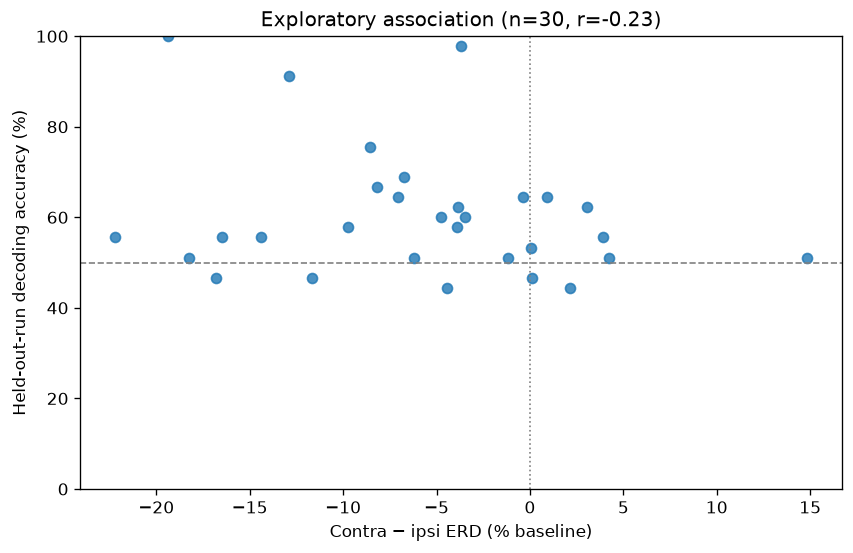

Pearson r is descriptive only; no inferential claim is made.


In [8]:
if len(rows) < 5:
    print("Need results for at least five participants to plot this exploratory relationship.")
else:
    x = np.array([float(r["laterality_erd_pct"]) for r in rows])
    y = np.array([float(r["accuracy"]) for r in rows]) * 100
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < 5 or np.std(x[valid]) == 0 or np.std(y[valid]) == 0:
        print("Insufficient variation to examine the correlation.")
    else:
        r = np.corrcoef(x[valid], y[valid])[0, 1]
        fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
        ax.scatter(x[valid], y[valid], alpha=0.8)
        ax.axhline(50, color="gray", linestyle="--", linewidth=1)
        ax.axvline(0, color="gray", linestyle=":", linewidth=1)
        ax.set(xlabel="Contra − ipsi ERD (% baseline)",
               ylabel="Held-out-run decoding accuracy (%)",
               ylim=(0, 100), title=f"Exploratory association (n={valid.sum()}, r={r:+.2f})")
        show_figure(fig)
        print("Pearson r is descriptive only; no inferential claim is made.")

## 9. Interpret, verify, and extend

Questions to investigate after examining the figures:

- Do the C3/C4 time–frequency patterns show consistent **task-related** power changes, or do they differ substantially across recording runs?
- Are low decoding accuracies associated with weaker lateralization, greater noise, or fewer usable trials? **Check individual recordings before attributing differences to participants.**
- How does performance change with different frequency bands or numbers of CSP components? Choose parameters using **training data only** to avoid optimistic estimates.
- Could a classifier trained on some participants work for an **unseen participant**? This requires *subject-held-out* evaluation, not the within-participant results reported here.

**Reproducibility:** Input EDF files belong in `data/` and derived files in `results/`; both are excluded from GitHub. Share the notebook and code, not the raw recordings. Rerun this notebook and check its displayed figures before drawing conclusions. Results will depend on the exact files, preprocessing choices, and package versions. The accompanying [README](README.md) explains the full methodology and limitations.